In [ ]:
import pandas as pd
from tensorflow import keras
from sklearn.model_selection import train_test_split

# Yêu cầu 1: Đọc dữ liệu từ file sepsis.csv. Chia dữ liệu thành 2 phần: training (80%) và phần còn lại cho testing (20%).
# 1.1. Đọc file .csv sử dụng pandas
columns = ['LOS', 'GENDER', 'AGE', 'WEIGHT', 'GCS TOTAL', 'TEMPERATURE', 'OUTCOME']
df = pd.read_csv('/content/drive/MyDrive/Học máy cơ bản/Practice02/sepsis.csv', usecols = columns)

# 1.2. Chia dữ liệu: train (80% = 2585) and test (20% = 647)
X = df[['LOS', 'GENDER', 'AGE', 'WEIGHT', 'GCS TOTAL', 'TEMPERATURE']]

y = df['OUTCOME']
train_size = 2585
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

# 1.3. Mã hóa One-hot (One-hot encoding)
y_train_onehot = keras.utils.to_categorical(y_train, 2)
y_test_onehot = keras.utils.to_categorical(y_test, 2)

print("Number of Training samples:", len(X_train))
print("Number of Testing samples:", len(X_test))

Number of Training samples: 2585
Number of Testing samples: 647


In [ ]:
# Yêu cầu 2: Xây dựng mạng nơ-ron có tên model_sepsis có 4 lớp ẩn (Mạng nơ-ron này có 6 lớp: 1 Input layer, 4 Hidden layers 8, 16, 32 và 8 nơ-ron, 1 Output layer.
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential

# 2.1. Xây dựng mạng nơ-ron với 4 lớp ẩn
def model_sepsis():

    model = Sequential()

    # Xây dựng mạng: 1 Input + 4 Hidden + 1 Output
    model.add(Dense(8, input_dim=6, activation='relu'))
    model.add(Dense(16, activation='relu'))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(8, activation='relu'))
    model.add(Dense(2, activation='softmax'))

    return model

# 2.2 Chọn model (1 lớp ẩn hay nhiều lớp ẩn)
model = model_sepsis()

# 2.3. Hiển thị thông tin model
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,026 (4.01 KB)

 Trainable params: 1,026 (4.01 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Yêu cầu 3: Lựa chọn hàm loss và tối ưu hoá cho mô hình đó.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

Epoch 1/80
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7321 - loss: 0.5479 - val_accuracy: 0.7118 - val_loss: 0.6259
Epoch 2/80
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7326 - loss: 0.5442 - val_accuracy: 0.7176 - val_loss: 0.6204
Epoch 3/80
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7331 - loss: 0.5448 - val_accuracy: 0.7195 - val_loss: 0.6376
Epoch 4/80
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7336 - loss: 0.5434 - val_accuracy: 0.7234 - val_loss: 0.5948
Epoch 5/80
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7379 - loss: 0.5379 - val_accuracy: 0.7137 - val_loss: 0.5988
Epoch 6/80
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7374 - loss: 0.5388 - val_accuracy: 0.7157 - val_loss: 0.6139
Epoch 7/80
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7374 - loss: 0.5438 - val_accuracy: 0.7273 - val_loss: 0.6070
Epoch 8/80
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7326 - loss: 0.5428 - val_accuracy: 0.

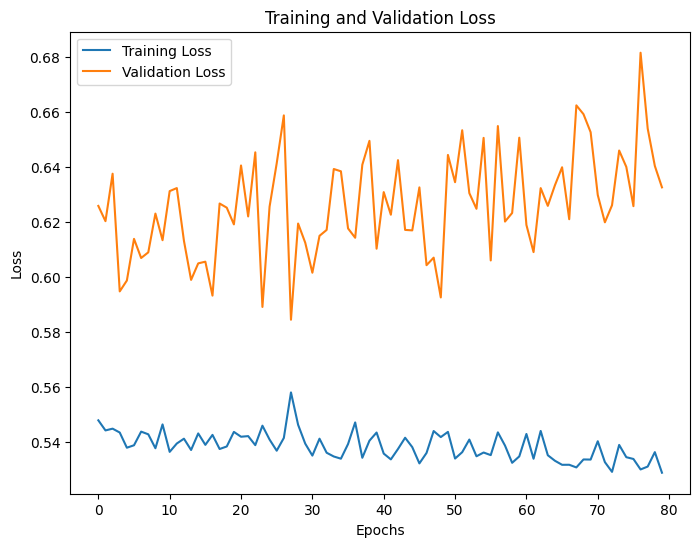

In [19]:
# Yêu cầu 4: Tiến thành training mạng nơ-ron đã xây dựng trên tập dữ liệu đã được xử lý ở bước 1 với 100 epochs và lưu lại các model đã huấn luyện.
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.layers import Dropout

# 4.1. Training model (có nhiều tuỳ chọn). Một số tham số:
history = model.fit(X_train, y_train_onehot, validation_split=0.2, epochs=100, batch_size=16)
# Test loss: 0.606336236000061
# Test accuracy: 0.7202472686767578

# Yêu cầu 6: Huấn luyện lại mô hình 50 epochs và đánh giá lại trên tập testing. Xem kết quả có cải thiện hay không?
# history = model.fit(X_train, y_train_onehot, validation_split=0.2, epochs=50, batch_size=16)
# Test loss: 0.6186034083366394
# Test accuracy: 0.7109737396240234

# Yêu cầu 7: Huấn luyện lại mô hình 80 epochs và đánh giá lại trên tập testing. Xem kết quả có cải thiện hay không?
# history = model.fit(X_train, y_train_onehot, validation_split=0.2, epochs=80, batch_size=16)
# Test loss: 0.6448338031768799
# Test accuracy: 0.7187017202377319

# 4.2. Lưu model
model.save('modelNN_model.h5')

# 4.3. Hiển thị Training and Validation Loss
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [22]:
# Yêu cầu 5: Đánh giá model đã được training trên tập testing.
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 5.1. Hiển thị kết quả (accuracy) trên tập testing
test_loss, test_acc = model.evaluate(X_test, y_test_onehot)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

from tensorflow.keras.models import Sequential, Model, load_model, Sequential
# 5.2. Load lại model
model_loaded = load_model('modelNN_model.h5')

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7187 - loss: 0.6448 


Test loss: 0.6448338031768799
Test accuracy: 0.7187017202377319
